# 01 · Residue interaction network (RIN) and criticality analysis

Human lysosomal acid α-glucosidase (GAA), PDB 5NN3 (Rosetta-relaxed), chain A.

This notebook rebuilds every network quantity from the raw RINerator output and follows the steps of the original `full_rin_analysis` notebook:

1. Load the RINerator network and build the graph
2. Compute the graph features (centralities)
3. Check the residues with zero betweenness and the "disconnected" residues removed in earlier drafts
4. Add the structural (Chimera) and conservation (ConSurf-DB) features and the mutation labels
5. Correlation between the graph features
6. Criticality groups (LDLB / LDHB / HDHB) by K-means binning → **Fig. 3a**
7. Supercritical hubs by the Euclidean distance to the ideal point → **Fig. 3c**
8. Mutation positions in the groups → **Fig. 3e**
9. Solvent exposure and conservation of the groups → **Fig. 4c, d**
10. Mutation vs no-mutation feature comparison → **Fig. S1, Table S2**
11. Reproduction of the earlier 811-residue analysis

In [1]:
%matplotlib inline
import sys, json, inspect, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from gaa_hotspot import data, network, stats, ml, figures as F
from gaa_hotspot import sss as sss_mod
from gaa_hotspot.common import AA, MODEL_ORDER, MODEL_NAMES, config, raw, read_processed, table, load_values
from gaa_hotspot.plotting import apply_style, MODEL_COLOURS, MODEL_LABELS, MODEL_SHORT, V7_MODEL_ORDER

apply_style()
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
cfg = config()
V = load_values()
print("project root:", ROOT)

project root: Pompe-GAA-Hotspots


## 1. Object for analysis

Raw input files used in this notebook:

In [2]:
prot = "5NN3_relaxed"
for sub in ["structure", "rin", "chimera", "conservation", "labels"]:
    for f in sorted(raw(sub).glob("*")):
        print(f"{sub:13s} {f.name:42s} {f.stat().st_size / 1024:9.1f} kB")

structure     5NN3_relaxed.pdb                              1256.2 kB
rin           5NN3_relaxed_h.sif                             322.3 kB
rin           5NN3_relaxed_h_intsc.ea                        422.0 kB
rin           5NN3_relaxed_h_nrint.ea                        359.2 kB
chimera       areaSAS.txt                                     20.9 kB
chimera       areaSES.txt                                     21.0 kB
chimera       kdhydro.txt                                     10.4 kB
chimera       phi.txt                                         17.5 kB
chimera       psi.txt                                         20.9 kB
chimera       relSESA.txt                                     13.4 kB
conservation  5NN3_consurf_grades.txt                        126.4 kB
conservation  5NN3_relaxed_ConsurfDB_data.xlsx                74.2 kB
labels        GAA_mutation_positions.csv                       5.8 kB


## 2. RINerator network

The SIF file lists one typed interaction per line (`A:<residue>:_:<aa>  <type>  A:<residue>:_:<aa>`).

In [3]:
sif = raw("rin", f"{prot}_h.sif").read_text().splitlines()
print(len(sif), "lines in the SIF file\n")
print(*sif[:8], sep="\n")

9268 lines in the SIF file

A:87:_:ASN cnt:mc_sc A:324:_:PRO
A:140:_:ASN cnt:sc_sc A:139:_:GLU
A:140:_:ASN cnt:mc_sc A:139:_:GLU
A:225:_:GLN cnt:sc_sc A:207:_:PRO
A:316:_:ASN cnt:sc_sc A:569:_:TYR
A:316:_:ASN cnt:mc_sc A:570:_:ASN
A:316:_:ASN cnt:mc_sc A:569:_:TYR
A:323:_:GLN cnt:mc_sc A:89:_:ARG


In [4]:
typed = data.rin_edges()          # (u, v, interaction type); self-pairs removed
print("typed interactions:", len(typed))
typed["type"].value_counts().to_frame("count")

typed interactions: 9268


,count
type,
combi:all_all,3475
cnt:mc_sc,1949
cnt:mc_mc,1636
cnt:sc_sc,1520
hbond:mc_mc,378
hbond:mc_sc,191
hbond:sc_sc,99
ovl:mc_sc,10
ovl:mc_mc,5


A residue pair can be joined by several interaction types (e.g. a side-chain contact and a hydrogen bond). The graph uses each **distinct residue pair once**:

In [5]:
pairs = typed[["u", "v"]].drop_duplicates()
multi = (typed.groupby(["u", "v"]).size() > 1).sum()
print("unique residue-residue contacts:", len(pairs))
print("pairs joined by more than one interaction type:", int(multi))

unique residue-residue contacts: 3475
pairs joined by more than one interaction type: 3475


In [6]:
g = network.build_graph(typed)
comps = g.components()
nodes = sorted(int(n) for n in g.vs["name"])
gaps = sorted(set(range(nodes[0], nodes[-1] + 1)) - set(nodes))
print(f"nodes: {g.vcount()}   edges: {g.ecount()}   connected components: {len(comps)}   connected: {g.is_connected()}")
print(f"residue range: {nodes[0]}-{nodes[-1]}")
print(f"{len(gaps)} residue numbers inside this range are not in the model (unresolved in the crystal structure):")
print(gaps)

nodes: 844   edges: 3475   connected components: 1   connected: True
residue range: 81-952
28 residue numbers inside this range are not in the model (unresolved in the crystal structure):
[116, 117, 118, 119, 120, 121, 122, 198, 199, 200, 201, 202, 203, 204, 782, 783, 784, 785, 786, 787, 788, 789, 790, 791, 792, 793, 794, 938]


## 3. Graph features of the RIN

| feature | meaning |
|---|---|
| degree | number of residues in contact |
| betweenness | number of shortest paths passing through the residue |
| closeness | inverse mean shortest-path length to all other residues |
| burt | Burt's constraint (low = bridges otherwise separate neighbourhoods) |
| authority | HITS authority score |
| page_rank | PageRank |
| k_core | largest k such that the residue is in the k-core |

In [7]:
df_graph_features = network.centralities(g)
print(df_graph_features.shape)
df_graph_features.head()

(844, 8)


,degree,betweenness,closeness,burt,authority,page_rank,k_core,log_betweenness
residue,,,,,,,,
81,4,62.4192,0.1032,0.3633,0.0002,0.0008,3,1.8022
82,6,260.8814,0.1099,0.2848,0.0005,0.0011,4,2.4181
83,3,25.8998,0.1061,0.5180,0.0002,0.0007,3,1.4297
84,7,1363.6412,0.1184,0.2306,0.0009,0.0013,4,3.1350
85,5,8.6444,0.1169,0.3883,0.0010,0.0009,4,0.9843


In [8]:
df_graph_features.describe().T

,count,mean,std,min,25%,50%,75%,max
degree,844.0,8.2346,2.8035,1.0000e+00,6.0000,8.0000,10.0000,18.0000
betweenness,844.0,2505.1280,3121.7379,0.0000e+00,412.6371,1391.5304,3361.8433,18584.8353
closeness,844.0,0.1471,0.0213,9.8092e-02,0.1316,0.1457,0.1631,0.1984
burt,844.0,0.2456,0.1063,1.1576e-01,0.1757,0.2138,0.2801,1.0000
authority,844.0,0.1100,0.1464,3.7244e-05,0.0156,0.0535,0.1440,1.0000
page_rank,844.0,0.0012,0.0003,3.2287e-04,0.0010,0.0012,0.0014,0.0022
k_core,844.0,4.9526,0.8822,1.0000e+00,5.0000,5.0000,6.0000,6.0000
log_betweenness,844.0,2.9392,0.8862,0.0000e+00,2.6166,3.1438,3.5267,4.2692


## 4. Important preprocessing: zero betweenness

The earlier notebook removed residues with zero betweenness before taking log10(betweenness), because log10(0) = −∞.
Here all residues are kept and the feature is **log10(1 + betweenness)**, which is defined for every residue and identical in shape for the others.

In [9]:
zero_betweenness = df_graph_features.query("betweenness == 0").index.tolist()
original_zero = [97, 114, 155, 187, 189, 206, 226, 288, 418, 419, 508, 531, 678, 686, 799, 849, 850, 882, 894, 912, 914, 924, 931, 940, 946]
print(len(zero_betweenness), "residues with zero betweenness:", zero_betweenness)
print("same list as the earlier notebook:", zero_betweenness == original_zero)
df_graph_features.loc[zero_betweenness, ["degree", "closeness", "k_core"]].T

25 residues with zero betweenness: [97, 114, 155, 187, 189, 206, 226, 288, 418, 419, 508, 531, 678, 686, 799, 849, 850, 882, 894, 912, 914, 924, 931, 940, 946]
same list as the earlier notebook: True


residue,97,114,155,187,189,206,226,288,418,419,508,531,678,686,799,849,850,882,894,912,914,924,931,940,946
degree,1.0000,2.0000,3.000,3.000,2.0000,2.0000,2.0000,1.0000,3.000,4.000,4.0000,3.0000,2.0000,4.0000,2.0000,2.0000,3.0000,3.0000,4.000,3.0000,2.0000,2.0000,4.0000,3.0000,3.0000
closeness,0.1089,0.1037,0.114,0.116,0.1268,0.1213,0.1283,0.1385,0.122,0.122,0.1364,0.1185,0.1258,0.1378,0.1297,0.1164,0.1166,0.1058,0.125,0.1049,0.1005,0.0995,0.1126,0.1178,0.1153
k_core,1.0000,2.0000,3.000,3.000,2.0000,2.0000,2.0000,1.0000,3.000,4.000,4.0000,3.0000,2.0000,4.0000,2.0000,2.0000,3.0000,3.0000,4.000,3.0000,2.0000,2.0000,4.0000,3.0000,3.0000


## 5. The "disconnected" residues of the earlier notebook

The earlier notebook also removed a hard-coded list of 16 residues described as *disconnected*. The graph above is a single connected component, so every residue can be reached from every other one. The table shows each listed residue with its neighbours:

In [10]:
old_disconnected = [97, 206, 337, 288, 88, 831, 483, 651, 758, 814, 678, 799, 848, 946, 914, 924]
seq = data.structure_sequence()
giant = {int(g.vs[i]["name"]) for i in max(comps, key=len)}
rows = []
for r in sorted(old_disconnected):
    v = g.vs.find(name=str(r))
    rows.append({"residue": f"{seq[r]}{r}", "degree": v.degree(),
                 "neighbours": ", ".join(sorted((g.vs[n]["name"] for n in g.neighbors(v)), key=int)),
                 "betweenness": round(df_graph_features.loc[r, "betweenness"], 1),
                 "in_main_component": r in giant,
                 "mean_shortest_path": round(float(np.mean(g.distances(source=v)[0])), 2)})
pd.DataFrame(rows)

,residue,degree,neighbours,betweenness,in_main_component,mean_shortest_path
0,S88,6,"84, 85, 86, 89, 90, 323",421.6,True,8.09
1,A97,1,96,0.0,True,9.17
2,S206,2,"176, 207",0.0,True,8.23
3,G288,1,286,0.0,True,7.21
4,L337,8,"182, 183, 239, 241, 246, 248, 312, 336",2479.2,True,6.60
5,G483,6,"479, 480, 481, 482, 484, 485",603.0,True,7.21
6,G651,3,"618, 650, 679",354.6,True,6.78
7,L678,2,"676, 679",0.0,True,7.94
8,A758,5,"621, 656, 757, 759, 760",227.1,True,7.04
9,H799,2,"771, 798",0.0,True,7.70


In [11]:
labels = data.mutation_labels()
extra = [r for r in old_disconnected if r not in zero_betweenness]
print("listed as disconnected although betweenness > 0:", extra)
print("  of these, reported mutation positions:", [f"{seq[r]}{r}" for r in extra if labels.get(r, 0) == 1])
print("zero-betweenness residues that are mutation positions:", [f"{seq[r]}{r}" for r in zero_betweenness if labels.get(r, 0) == 1])
print(f"residues removed in the earlier analysis: {len(set(zero_betweenness) | set(old_disconnected))}  ->  844 - 33 = 811")

listed as disconnected although betweenness > 0: [337, 88, 831, 483, 651, 758, 814, 848]
  of these, reported mutation positions: ['G483']
zero-betweenness residues that are mutation positions: ['D419']
residues removed in the earlier analysis: 33  ->  844 - 33 = 811


## 6. log betweenness

Added to reduce the skew of betweenness:

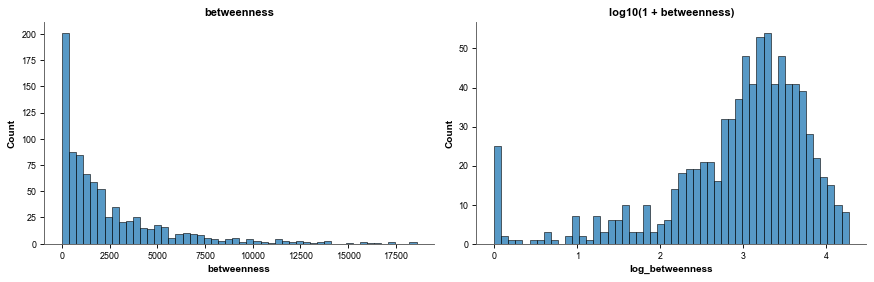

In [12]:
assert np.allclose(np.log10(1 + df_graph_features.betweenness), df_graph_features.log_betweenness)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df_graph_features.betweenness, bins=50, ax=axes[0]); axes[0].set_title("betweenness")
sns.histplot(df_graph_features.log_betweenness, bins=50, ax=axes[1]); axes[1].set_title("log10(1 + betweenness)")
plt.tight_layout(); plt.show()

## 7. Structural features (UCSF Chimera)

Chimera `save attribute` files, one residue per line:

In [13]:
print(*raw("chimera", "areaSAS.txt").read_text().splitlines()[:6], sep="\n")
df_structure = data.chimera_features()
print("\n", df_structure.shape)
display(df_structure.head())
print("missing values:", df_structure.isnull().sum().to_dict())

/A:81	175.4710039806716
/A:82	37.33130497212249
/A:83	146.14071466485038
/A:84	20.298601944248404
/A:85	82.84779328944435
/A:86	62.82284188

 (844, 6)


,areaSAS,areaSES,relSESA,kdhydro,phi,psi
residue,,,,,,
81,175.4710,70.9262,106.534,-3.5,NaN,-20.1156
82,37.3313,31.1494,78.620,2.5,-108.1770,13.6793
83,146.1407,80.4497,86.142,-3.5,-81.7587,69.5425
84,20.2986,38.5642,90.264,4.2,-109.2543,125.9927
85,82.8478,59.8015,81.030,-1.6,-55.6090,141.9399


missing values: {'areaSAS': 0, 'areaSES': 0, 'relSESA': 0, 'kdhydro': 0, 'phi': 3, 'psi': 2}


φ is undefined for the first residue and ψ for residues before a chain break, so a few values are missing. They are imputed with the training-fold median inside the cross-validation (notebook 02).

## 8. Conservation (ConSurf-DB)

Normalised ConSurf score per residue; **lower = more conserved**.

In [14]:
df_conserv = data.consurf_db_scores()
print(len(df_conserv), "residues with a ConSurf-DB score")
df_conserv.describe().to_frame().T

844 residues with a ConSurf-DB score


,count,mean,std,min,25%,50%,75%,max
conservation,844.0,-0.029,0.975,-1.553,-0.7622,-0.1935,0.682,2.492


## 9. Mutation labels

`mutation_observed = 1` for residue positions with a reported Pompe-disease missense mutation (HGMD-derived position list).

In [15]:
df_mutation = data.mutation_labels()
df_mutation.value_counts().rename({0: "no mutation", 1: "mutation position"})

mutation_observed
no mutation          630
mutation position    214
Name: count, dtype: int64

## 10. Making the full dataset

Merge graph, structural and conservation features and the labels; check that the result equals the pipeline file `data/processed/residue_features.csv`.

In [16]:
df_full = df_graph_features.join(df_structure, how="left").join(df_conserv, how="left").join(df_mutation, how="left")
df_full.insert(0, "wt", seq.reindex(df_full.index))
df_full["mutation_observed"] = df_full.mutation_observed.fillna(0).astype(int)
stored = read_processed("residue_features.csv").set_index("residue")
num = stored.select_dtypes("number").columns
print(df_full.shape)
print("identical to data/processed/residue_features.csv:",
      np.allclose(df_full[num].astype(float), stored[num].astype(float), equal_nan=True))
df_full.head()

(844, 17)
identical to data/processed/residue_features.csv: True


,wt,degree,betweenness,closeness,burt,authority,page_rank,k_core,log_betweenness,areaSAS,areaSES,relSESA,kdhydro,phi,psi,conservation,mutation_observed
residue,,,,,,,,,,,,,,,,,
81,Q,4,62.4192,0.1032,0.3633,0.0002,0.0008,3,1.8022,175.4710,70.9262,106.534,-3.5,NaN,-20.1156,0.037,0
82,C,6,260.8814,0.1099,0.2848,0.0005,0.0011,4,2.4181,37.3313,31.1494,78.620,2.5,-108.1770,13.6793,-0.816,0
83,D,3,25.8998,0.1061,0.5180,0.0002,0.0007,3,1.4297,146.1407,80.4497,86.142,-3.5,-81.7587,69.5425,1.280,0
84,V,7,1363.6412,0.1184,0.2306,0.0009,0.0013,4,3.1350,20.2986,38.5642,90.264,4.2,-109.2543,125.9927,0.680,0
85,P,5,8.6444,0.1169,0.3883,0.0010,0.0009,4,0.9843,82.8478,59.8015,81.030,-1.6,-55.6090,141.9399,0.862,0


mutation_observed
0    74.64
1    25.36
Name: proportion, dtype: float64


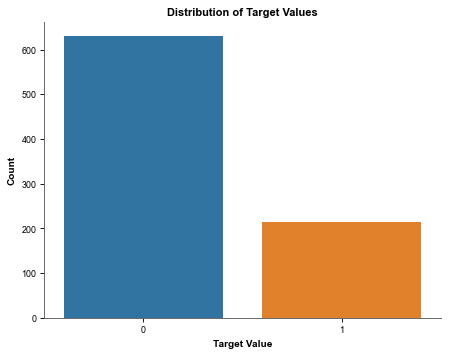

In [17]:
print(df_full.mutation_observed.value_counts(normalize=True).mul(100).round(2))
sns.countplot(x="mutation_observed", data=df_full, hue="mutation_observed", legend=False)
plt.title("Distribution of Target Values"); plt.xlabel("Target Value"); plt.ylabel("Count"); plt.show()

## 11. Graph feature correlations

Absolute correlation between the seven centralities (lower triangle), for the three correlation methods used in the original notebook. Burt's constraint is negatively correlated with the others; the sign is in Supplementary Table S3.

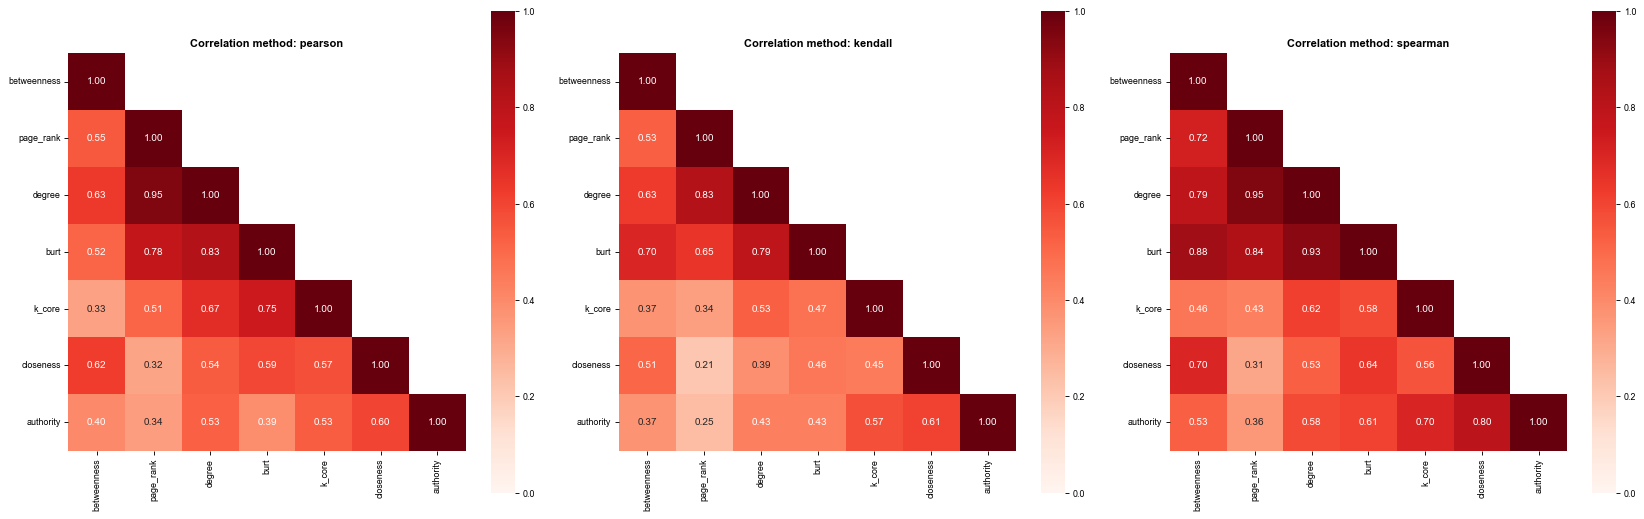

In [18]:
graph_features = ["betweenness", "page_rank", "degree", "burt", "k_core", "closeness", "authority"]
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, method in zip(axes, ["pearson", "kendall", "spearman"]):
    c = df_full[graph_features].corr(method=method)
    mask = np.triu(np.ones_like(c, dtype=bool)); np.fill_diagonal(mask, False)
    sns.heatmap(c.abs(), annot=True, fmt=".2f", vmin=0, vmax=1, square=True, cmap="Reds", mask=mask, ax=ax)
    ax.set_title(f"Correlation method: {method}")
plt.tight_layout(); plt.show()

## 12. Critical residue analysis (criticality)

Degree against log betweenness; the LDLB, LDHB and HDHB regions are visible as corners of the distribution.

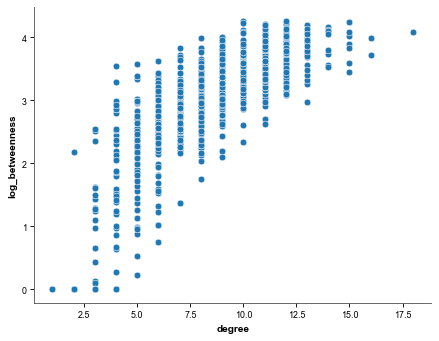

In [19]:
sns.scatterplot(data=df_full, x="degree", y="log_betweenness")
plt.show()

K-means binning (4 bins) of log betweenness and degree, exactly as `analysis_utils.find_criticality_intervals(..., type_bins='kmeans')` in the original code:

In [20]:
from sklearn.preprocessing import KBinsDiscretizer
kbd = KBinsDiscretizer(n_bins=cfg["criticality"]["kbins"], encode="ordinal", strategy="kmeans", random_state=cfg["seed"])
bins = kbd.fit_transform(df_full[["log_betweenness", "degree"]])
lb_edges, deg_edges = np.sort(kbd.bin_edges_[0]), np.sort(kbd.bin_edges_[1])
lb_intervals = [pd.Interval(a, b, closed="both") for a, b in zip(lb_edges[:-1], lb_edges[1:])]
degree_intervals = [pd.Interval(a, b, closed="both") for a, b in zip(deg_edges[:-1], deg_edges[1:])]
print("log betweenness intervals:"); display(lb_intervals)
print("degree intervals:"); display(degree_intervals)

log betweenness intervals:


[Interval(0.0, 1.2174103529395897, closed='both'),
 Interval(1.2174103529395897, 2.550445310150642, closed='both'),
 Interval(2.550445310150642, 3.36219388065004, closed='both'),
 Interval(3.36219388065004, 4.269182084814069, closed='both')]

degree intervals:


[Interval(1.0, 5.889973210868732, closed='both'),
 Interval(5.889973210868732, 9.256198515618626, closed='both'),
 Interval(9.256198515618626, 12.33508977361436, closed='both'),
 Interval(12.33508977361436, 18.0, closed='both')]

Classification rule (`classify_critical`):
- **LDLB**: lowest degree bin *and* lowest log-betweenness bin
- **HDHB**: highest degree bin *and* highest log-betweenness bin
- **LDHB**: lowest degree bin *and* highest log-betweenness bin
- everything else: None

In [21]:
lb_bin, deg_bin = bins[:, 0], bins[:, 1]
top = cfg["criticality"]["kbins"] - 1
df_full["criticality"] = np.select([(deg_bin == 0) & (lb_bin == 0), (deg_bin == top) & (lb_bin == top), (deg_bin == 0) & (lb_bin == top)],
                                   ["LDLB", "HDHB", "LDHB"], "None")
groups = read_processed("residue_network_groups.csv").set_index("residue")
print("identical to the pipeline:", bool((groups.criticality.replace({"Other": "None"}) == df_full.criticality).all()))
df_full.criticality.value_counts()

identical to the pipeline: True


criticality
None    756
LDLB     45
HDHB     39
LDHB      4
Name: count, dtype: int64

### Figure 3a — criticality quadrants

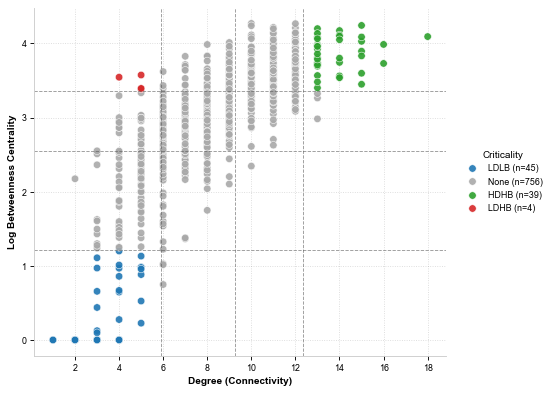

In [22]:
F.fig3a_criticality(df_full, groups, {"log_betweenness": lb_edges, "degree": deg_edges})
plt.show()

In [23]:
for gname in ["LDLB", "LDHB", "HDHB"]:
    res = df_full.index[df_full.criticality == gname]
    print(f"{gname} ({len(res)}):", ", ".join(f"{df_full.wt[r]}{r}" for r in res), "\n")

LDLB (45): P85, A97, T99, E101, P112, K114, S144, E145, T155, T156, A187, R189, S206, L226, D227, G288, K418, D419, S449, A452, T472, D508, D531, N535, S654, L678, S686, E689, G759, A761, H799, E801, K849, G850, E869, N882, S894, A912, Q914, G920, S924, P930, D931, S940, Q946 

LDHB (4): E196, T197, S265, I780 

HDHB (39): R106, R224, L278, Y292, Y298, H308, F342, V350, Y354, L355, F371, Y378, M391, W498, W499, F506, Y575, E579, L587, H606, L632, F634, N635, R660, W661, T662, L664, Y668, M695, R702, L705, P707, Y710, F713, W738, Q743, Y766, Y773, L847 



## 13. Supercritical residues through the Euclidean distance method

The ideal point is the maximum of degree, log betweenness and closeness; residues closest to it are the best trade-off (supercritical) hubs.

In [24]:
from scipy.spatial.distance import cdist
pts = df_full[["degree", "log_betweenness", "closeness"]]
ideal_point = pts.max().values
print("ideal point (degree, log betweenness, closeness):", ideal_point.round(4))
df_full["distance_from_ideal"] = cdist(pts.values, ideal_point.reshape(1, -1)).ravel()
best_trade_off_points = df_full.sort_values("distance_from_ideal").head(cfg["criticality"]["n_supercritical"])
best_trade_off_points[["wt", "degree", "log_betweenness", "closeness", "distance_from_ideal", "criticality", "mutation_observed"]]

ideal point (degree, log betweenness, closeness): [18.      4.2692  0.1984]


,wt,degree,log_betweenness,closeness,distance_from_ideal,criticality,mutation_observed
residue,,,,,,,
661,W,18,4.0920,0.1783,0.1783,HDHB,1
499,W,16,3.9858,0.1672,2.0202,HDHB,1
660,R,16,3.7294,0.1625,2.0719,HDHB,1
575,Y,15,4.2422,0.1734,3.0002,HDHB,1
713,F,15,4.0863,0.1856,3.0056,HDHB,0
710,Y,15,4.0277,0.1741,3.0098,HDHB,0
292,Y,15,3.8948,0.1811,3.0233,HDHB,1
350,V,15,3.8316,0.1761,3.0318,HDHB,1
498,W,15,3.5970,0.1541,3.0747,HDHB,0


In [25]:
sc_list = best_trade_off_points.index.tolist()
print("SUPERCRITICAL RESIDUES:", ", ".join(f"{df_full.wt[r]}{r}" for r in sc_list))
print("same 10 residues as the earlier notebook:", sorted(sc_list) == sorted([292, 350, 710, 713, 391, 499, 575, 498, 661, 660]))
print("identical to the pipeline:", set(sc_list) == set(groups.index[groups.supercritical]))
print("all in HDHB:", bool((best_trade_off_points.criticality == "HDHB").all()))
print("reported mutation positions among them:", int(best_trade_off_points.mutation_observed.sum()), "of", len(sc_list),
      "->", [f"{df_full.wt[r]}{r}" for r in sc_list if df_full.mutation_observed[r] == 1])

SUPERCRITICAL RESIDUES: W661, W499, R660, Y575, F713, Y710, Y292, V350, W498, M391
same 10 residues as the earlier notebook: True
identical to the pipeline: True
all in HDHB: True
reported mutation positions among them: 6 of 10 -> ['W661', 'W499', 'R660', 'Y575', 'Y292', 'V350']


### Figure 3c — 3D topological space and distance to the ideal hub

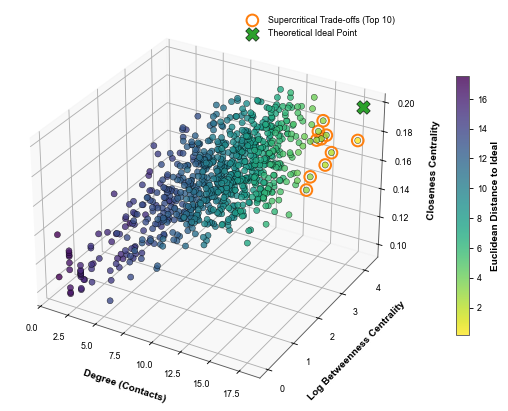

In [26]:
F.fig3c_supercritical_3d(df_full, groups)
plt.show()

**Sensitivity check.** The three axes have very different ranges, so the unscaled distance is dominated by degree. Repeating the selection on z-scored axes:

In [27]:
print("axis ranges  degree:", np.ptp(pts.degree), "  log betweenness:", round(np.ptp(pts.log_betweenness), 2), "  closeness:", round(np.ptp(pts.closeness), 3))
z = (pts - pts.mean()) / pts.std(ddof=0)
dz = pd.Series(cdist(z.values, z.max().values.reshape(1, -1)).ravel(), index=pts.index)
sc_z = dz.nsmallest(10).index
print("z-scored hubs:", ", ".join(f"{df_full.wt[r]}{r}" for r in sc_z))
print("shared with the unscaled set:", len(set(sc_z) & set(sc_list)), "of 10")

axis ranges  degree: 17   log betweenness: 4.27   closeness: 0.1
z-scored hubs: W661, F713, Y292, F634, Y668, V350, Y710, Y575, W499, R702
shared with the unscaled set: 7 of 10


## 14. Mutation positions in the criticality groups

In [28]:
from scipy.stats import fisher_exact
rows = []
for gname in ["HDHB", "LDHB", "LDLB", "None"]:
    sel = df_full.criticality == gname
    rows.append({"group": gname, "n": int(sel.sum()), "mutation_positions": int(df_full.mutation_observed[sel].sum()),
                 "fraction_mutated": df_full.mutation_observed[sel].mean()})
rows.append({"group": "SC (subset of HDHB)", "n": len(sc_list), "mutation_positions": int(best_trade_off_points.mutation_observed.sum()),
             "fraction_mutated": best_trade_off_points.mutation_observed.mean()})
display(pd.DataFrame(rows))
res = fisher_exact(pd.crosstab(df_full.criticality == "HDHB", df_full.mutation_observed).values)
print(f"HDHB vs all other residues, odds ratio of being a mutation position = {res.statistic:.2f}, Fisher exact P = {res.pvalue:.2e}")
print(f"overall fraction of mutation positions: {df_full.mutation_observed.mean():.3f}")

,group,n,mutation_positions,fraction_mutated
0,HDHB,39,20,0.5128
1,LDHB,4,0,0.0000
2,LDLB,45,2,0.0444
3,None,756,192,0.2540
4,SC (subset of HDHB),10,6,0.6000


HDHB vs all other residues, odds ratio of being a mutation position = 3.32, Fisher exact P = 4.53e-04
overall fraction of mutation positions: 0.254


### Figure 3e — overlap of mutation positions, HDHB residues and supercritical hubs

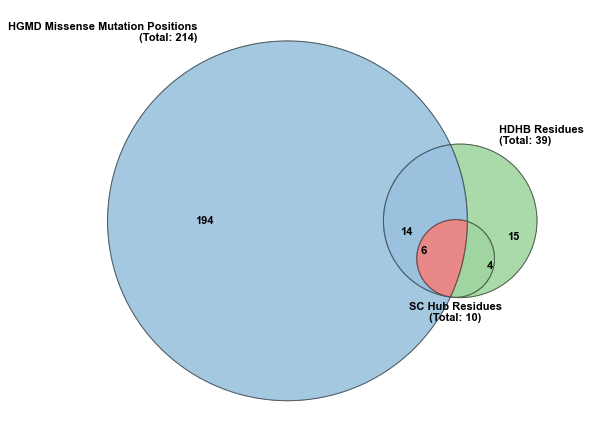

In [29]:
F.fig3e_venn(df_full, groups)
plt.show()

## 15. areaSAS and conservation score vs criticality

First the quick strip plots of the original notebook, then the manuscript panels (Fig. 4c, d), where the 10 supercritical hubs are shown as their own group (SC) and removed from HDHB.

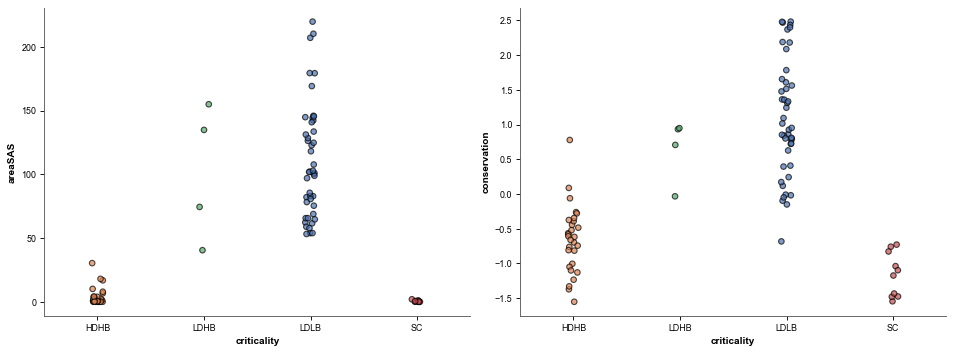

In [30]:
plot_df = df_full.assign(criticality=F.plot_groups(groups))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ["areaSAS", "conservation"]):
    sns.stripplot(data=plot_df.query("criticality != 'None'"), x="criticality", y=col, hue="criticality",
                  edgecolor="black", alpha=.7, size=5, linewidth=1.0, jitter=0.05, order="HDHB LDHB LDLB SC".split(),
                  palette="deep", legend=False, ax=ax)
plt.tight_layout(); plt.show()

In [31]:
from scipy.stats import kruskal
for col in ["areaSAS", "conservation"]:
    med = plot_df.query("criticality != 'None'").groupby("criticality")[col].median().round(3).to_dict()
    p = kruskal(*[df_full.loc[df_full.criticality == g, col] for g in ["HDHB", "LDHB", "LDLB"]]).pvalue
    print(f"{col:13s} medians {med}   Kruskal-Wallis (HDHB, LDHB, LDLB) P = {p:.2e}")

areaSAS       medians {'HDHB': 1.297, 'LDHB': 104.614, 'LDLB': 101.818, 'SC': 0.112}   Kruskal-Wallis (HDHB, LDHB, LDLB) P = 1.00e-14
conservation  medians {'HDHB': -0.617, 'LDHB': 0.82, 'LDLB': 0.952, 'SC': -1.135}   Kruskal-Wallis (HDHB, LDHB, LDLB) P = 1.12e-13


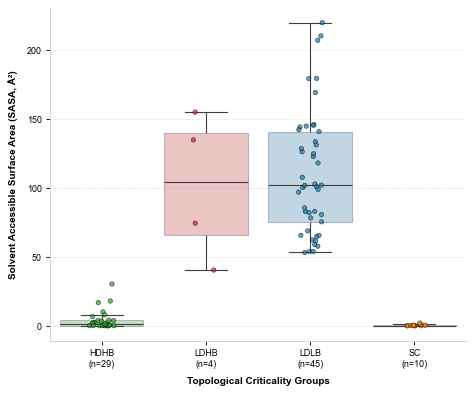

In [32]:
F.fig4_group_profile(df_full, groups, "areaSAS", "Solvent Accessible Surface Area (SASA, Å²)")
plt.show()

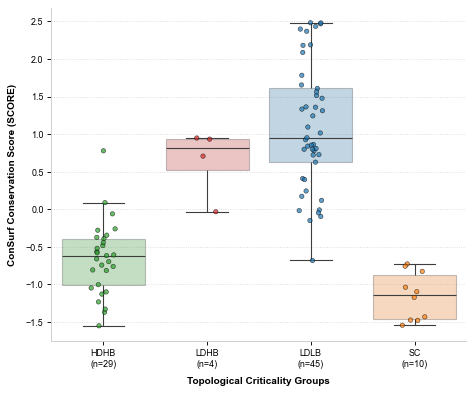

In [33]:
F.fig4_group_profile(df_full, groups, "conservation", "ConSurf Conservation Score (SCORE)")
plt.show()

## 16. Difference of feature means between mutated and non-mutated residues

Two-sided permutation test of the difference in means (10,000 label permutations, all residues), Benjamini–Hochberg q-values, Cohen's d.

In [34]:
features = cfg["features"] + ["betweenness"]
df_full[features].groupby(df_full["mutation_observed"]).mean().T.rename(columns={0: "mean_no_mutation", 1: "mean_mutation"})

mutation_observed,mean_no_mutation,mean_mutation
degree,7.8825,9.2710
log_betweenness,2.8232,3.2809
closeness,0.1436,0.1577
burt,0.2609,0.2006
authority,0.0992,0.1417
page_rank,0.0012,0.0013
k_core,4.8381,5.2897
kdhydro,-0.0197,-0.4626
areaSAS,41.0328,11.5412
areaSES,41.6768,22.4863


In [35]:
rng = np.random.default_rng(cfg["seed"])
y = df_full.mutation_observed
rows = []
for f in features:
    x1, x0 = df_full.loc[y == 1, f].dropna().values, df_full.loc[y == 0, f].dropna().values
    rows.append({"feature": f, "mean_mutation": x1.mean(), "mean_other": x0.mean(), "cohens_d": stats.cohens_d(x1, x0),
                 "permutation_p": stats.permutation_mean_diff(x1, x0, 10_000, rng)})
fs = pd.DataFrame(rows)
fs["q_BH"] = stats.bh_fdr(fs.permutation_p.values)
fs["significance"] = fs.q_BH.map(F.stars)
stored_fs = pd.read_csv(table("feature_statistics.csv"))
print("identical to results/tables/feature_statistics.csv:", np.allclose(stored_fs.permutation_p, fs.permutation_p))
print("features with q < 0.05:", int((fs.q_BH < 0.05).sum()), "of", len(fs))
fs.sort_values("permutation_p")

identical to results/tables/feature_statistics.csv: True
features with q < 0.05: 11 of 15


,feature,mean_mutation,mean_other,cohens_d,permutation_p,q_BH,significance
0,degree,9.2710,7.8825,0.5069,9.9990e-05,0.0001,***
1,log_betweenness,3.2809,2.8232,0.5297,9.9990e-05,0.0001,***
2,closeness,0.1577,0.1436,0.6925,9.9990e-05,0.0001,***
3,burt,0.2006,0.2609,-0.5849,9.9990e-05,0.0001,***
4,authority,0.1417,0.0992,0.2923,9.9990e-05,0.0001,***
5,page_rank,0.0013,0.0012,0.3747,9.9990e-05,0.0001,***
6,k_core,5.2897,4.8381,0.5248,9.9990e-05,0.0001,***
8,areaSAS,11.5412,41.0328,-0.7408,9.9990e-05,0.0001,***
9,areaSES,22.4863,41.6768,-0.7405,9.9990e-05,0.0001,***
13,conservation,-0.7212,0.2061,-1.0442,9.9990e-05,0.0001,***


### Supplementary Figure S1

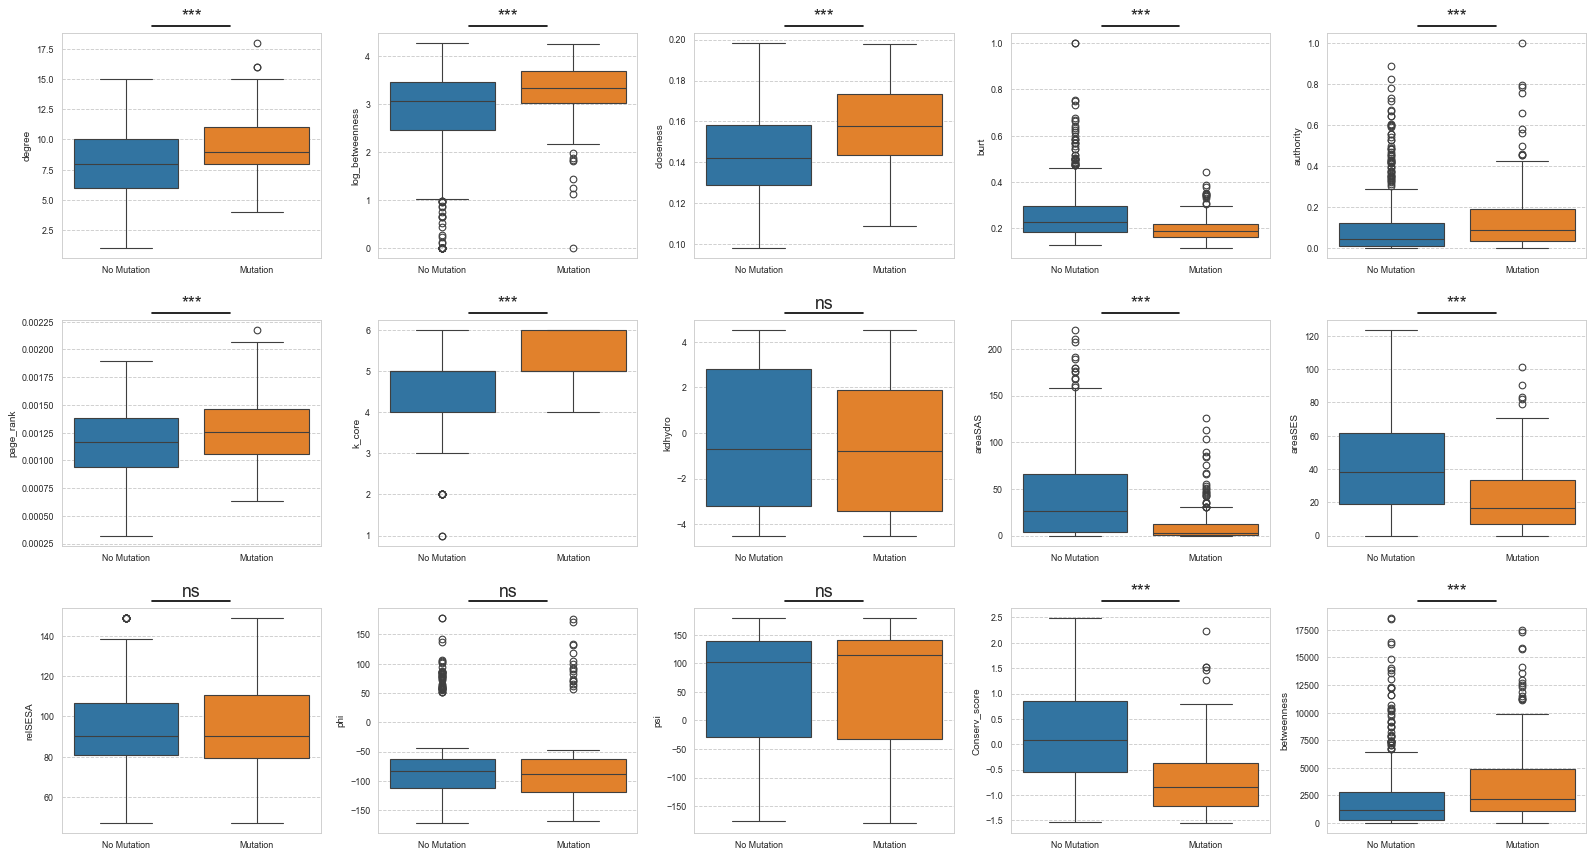

In [36]:
F.figS_feature_boxplots(df_full, stored_fs.set_index("feature"), features)
plt.show()

## 17. Reproducing the earlier 811-residue analysis

Applying the earlier filters (zero betweenness + hard-coded list, log10 betweenness) reproduces the published group sizes exactly, which confirms that only the residue filtering changed:

In [37]:
legacy = df_graph_features[(df_graph_features.betweenness > 0) & ~df_graph_features.index.isin(old_disconnected)].copy()
legacy["log_betweenness"] = np.log10(legacy.betweenness)
print("residues:", len(legacy), "  mutation positions:", int(df_mutation.reindex(legacy.index).fillna(0).sum()))
print("criticality groups:", network.criticality_groups(legacy, 4, cfg["seed"]).replace({"Other": "None"}).value_counts().to_dict())
print("supercritical hubs:", sorted(network.supercritical(legacy, 10, standardise=False).nsmallest(10).index.tolist()))

residues: 811   mutation positions: 212
criticality groups: {'None': 712, 'LDLB': 56, 'HDHB': 39, 'LDHB': 4}
supercritical hubs: [292, 350, 391, 498, 499, 575, 660, 661, 710, 713]


## Summary

In [38]:
ng = V["network_groups"]
print(f"RIN: {g.vcount()} residues, {g.ecount():,} contacts ({len(typed):,} typed interactions), one connected component")
print(f"mutation positions: {int(y.sum())} of {len(y)}")
for k, v in ng["groups"].items():
    print(f"{k}: {v['n']} residues, {v['n_mutation_positions']} mutation positions ({100 * v['fraction_mutated']:.1f}%)")
print("supercritical hubs:", ", ".join(ng["supercritical_hubs"]))
print(f"hubs at mutation positions: {ng['n_supercritical_mutated']}/10 ->", ", ".join(ng["supercritical_mutation_positions"]))
print(f"features differing between mutation and other positions (q < 0.05): {ng['n_features_significant_q05']} of 15")

RIN: 844 residues, 3,475 contacts (9,268 typed interactions), one connected component
mutation positions: 214 of 844
HDHB: 39 residues, 20 mutation positions (51.3%)
LDHB: 4 residues, 0 mutation positions (0.0%)
LDLB: 45 residues, 2 mutation positions (4.4%)
supercritical hubs: Y292, V350, M391, W498, W499, Y575, R660, W661, Y710, F713
hubs at mutation positions: 6/10 -> Y292, V350, W499, Y575, R660, W661
features differing between mutation and other positions (q < 0.05): 11 of 15
